# SokoBot benchmark analysis

Charts and exploration on top of the `sokostats` package (the `crunch` command prints the
same numbers as text). Put the CSVs in `data/` and point `MAPS_DIR` at the map folder.

In [1]:
from pathlib import Path

RUN_CSV = Path("data/new.csv")       # the run to analyse
COMPARE_CSV = Path("data/old.csv")   # optional second run; None to skip
MAPS_DIR = Path("../maps")           # folder with <map>.txt files
SLOW_MS = 1000

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sokostats import add_features, classify, compare_runs, load_run, rate_table, threads_that_ran

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa8"]
INK, MUTED, GRID = "#1f1f1e", "#5f5e58", "#e4e3de"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
pd.set_option("display.max_columns", 40, "display.width", 160)

run = load_run(RUN_CSV)
if MAPS_DIR.is_dir():
    run = add_features(run, MAPS_DIR)
run["result"] = classify(run)
RAN = threads_that_ran(run)
print(f"{len(run)} maps, line-up {run['lineup'].iloc[0]!r}, threads {RAN}")
print(f"solved {run['solved'].sum()} ({run['solved'].mean():.1%}), "
      f"invalid {int((run['solved'] & (run['valid'] != 1)).sum())}")
run["result"].value_counts()

2746 maps, line-up '0,1,3,4', threads [0, 1, 3, 4]
solved 2626 (95.6%), invalid 0


result
solved           2626
out of time       119
out of memory       1
Name: count, dtype: int64

## Why unsolved maps fail

In [3]:
unsolved = run[~run["solved"]]
pd.DataFrame({f"T{t}": unsolved[f"t{t}_outcome"].value_counts() for t in RAN}).fillna(0).astype(int)

,T0,T1,T3,T4
exhausted,5,25,5,0
pool_full,0,0,0,11
stopped,115,95,115,109


## Solve rate by feature

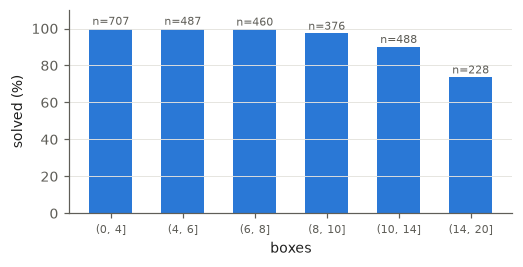

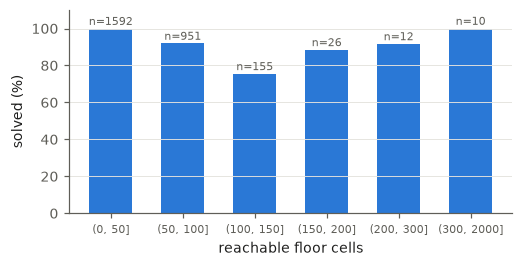

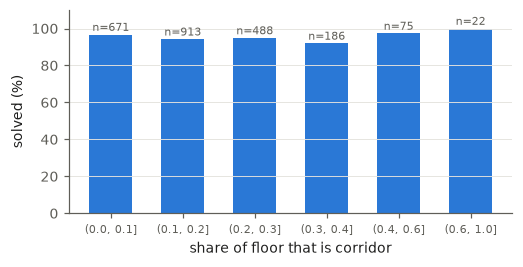

In [4]:
def plot_rate(column, bins, label):
    table = rate_table(run, column, bins)
    fig, ax = plt.subplots(figsize=(5.2, 2.4))
    ax.bar(range(len(table)), table["solved"] * 100, width=0.6, color=PALETTE[0])
    for i, (n, s) in enumerate(zip(table["maps"], table["solved"])):
        ax.text(i, s * 100 + 2, f"n={n}", ha="center", fontsize=7, color=MUTED)
    ax.set_xticks(range(len(table)), [str(b) for b in table.index], fontsize=7)
    ax.set_ylim(0, 110); ax.set_ylabel("solved (%)"); ax.set_xlabel(label)
    ax.grid(axis="x", visible=False)
    plt.show()

plot_rate("boxes", [0, 4, 6, 8, 10, 14, 20, 40], "boxes")
if "floor_cells" in run:
    plot_rate("floor_cells", [0, 50, 100, 150, 200, 300, 2000], "reachable floor cells")
    plot_rate("corridor_share", [0, .1, .2, .3, .4, .6, 1], "share of floor that is corridor")

## Speed of solved maps

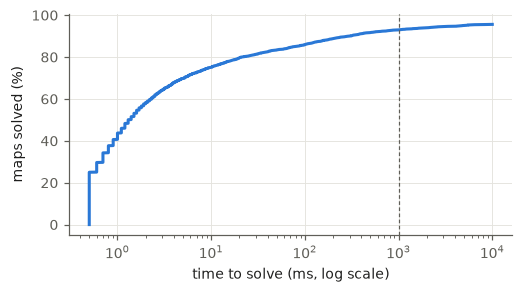

,map,thread,time_ms,nodes,boxes
166,15-32_Sokoban-Sasquatch-32,1,9980.4,10448492,14
329,2-104_Sokoban-Boxxle-1-104,4,8927.5,12096841,16
247,18-22_Sokoban-Sasquatch-IV-22,1,8295.8,7036723,9
1700,45-72_Sokoban-Atlas01-72,1,8284.7,6266801,15
383,22-21_Sokoban-Sasquatch-VIII-21,4,6457.0,5198922,14
1203,33-4_Sokoban-Alberto-Garcia-3-4,4,6257.1,2341611,13
106,1-29_Sokoban-Original-and-Extra-29,4,5785.0,7608143,16
777,2-70_Sokoban-Boxxle-1-70,4,5676.6,4774606,13
738,2-66_Sokoban-Boxxle-1-66,0,5513.7,5370775,12
67,10-9_Sokoban-The-Bagatelle-collection-9,4,5510.5,6057185,14


In [5]:
solved = run[run["solved"]]
t = np.sort(solved["time_ms"].clip(lower=0.5))
fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.plot(t, np.arange(1, len(t) + 1) / len(run) * 100, lw=2, color=PALETTE[0])
ax.set_xscale("log"); ax.set_xlabel("time to solve (ms, log scale)"); ax.set_ylabel("maps solved (%)")
ax.axvline(SLOW_MS, color=MUTED, lw=0.8, ls=(0, (3, 2)))
plt.show()
solved.nlargest(15, "time_ms")[["map", "thread", "time_ms", "nodes", "boxes"]]

## Who wins where

In [6]:
display(solved["thread"].value_counts().sort_index().rename(index=lambda t: f"T{t}").to_frame("wins"))
if "has_goal_room" in solved:
    display(pd.crosstab(solved["has_goal_room"], solved["thread"], normalize="index").round(2)
            .rename(columns=lambda t: f"T{t}"))

,wins
thread,
T0,653
T1,600
T3,441
T4,932


thread,T0,T1,T3,T4
has_goal_room,,,,
False,0.24,0.22,0.17,0.36
True,0.31,0.28,0.12,0.29


## Compare with a second run

change
same      2591
gained     145
lost        10
median time ratio 1.00


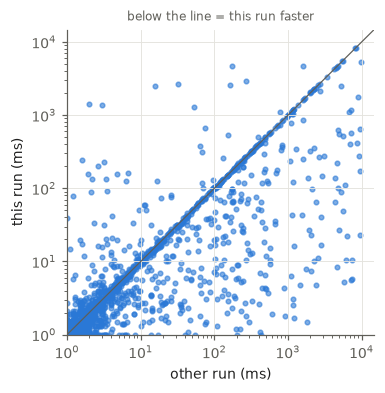

,map,solved_new,time_ms_new,thread_new,nodes_new,solved_old,time_ms_old,thread_old,nodes_old,change,ratio
4,100-14_Sokoban-TBox-14,True,882.0,4,601547,False,317.5,-1,465521,gained,NaN
44,100-50_Sokoban-TBox-50,True,209.7,4,177376,False,78.4,-1,129834,gained,NaN
64,10-5_Sokoban-The-Bagatelle-collection-5,True,2124.6,4,1841093,False,10042.8,-1,8075776,gained,NaN
65,10-6_Sokoban-The-Bagatelle-collection-6,True,148.8,4,216144,False,10017.2,-1,10221056,gained,NaN
67,10-9_Sokoban-The-Bagatelle-collection-9,True,5510.5,4,6057185,False,10018.6,-1,11087232,gained,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2619,8-7_Sokoban-The-DH1-collection-7,False,10027.8,-1,10223231,True,5412.3,2,5837725,lost,NaN
2650,94-9_Sokoban-81-9,True,756.0,4,1006951,False,10016.9,-1,11124992,gained,NaN
2651,9-4_Sokoban-The-DH2-collection-4,True,445.9,4,413005,False,10038.7,-1,7921024,gained,NaN
2694,97-21_Sokoban-Calx-21,True,20.3,4,11801,False,2.9,-1,4331,gained,NaN


In [7]:
if COMPARE_CSV is not None and COMPARE_CSV.exists():
    m = compare_runs(run, load_run(COMPARE_CSV))
    both = m.dropna(subset=["ratio"])
    print(m["change"].value_counts().to_string())
    print(f"median time ratio {both['ratio'].median():.2f}")
    fig, ax = plt.subplots(figsize=(3.6, 3.6))
    ax.scatter(both["time_ms_old"].clip(lower=1), both["time_ms_new"].clip(lower=1), s=9, color=PALETTE[0], alpha=0.6)
    lim = [1, max(both["time_ms_old"].max(), both["time_ms_new"].max()) * 1.5]
    ax.plot(lim, lim, color=MUTED, lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("other run (ms)"); ax.set_ylabel("this run (ms)")
    ax.set_title("below the line = this run faster", fontsize=8, color=MUTED)
    plt.show()
    display(m[m["change"] != "same"])